In [1]:
# ==============================================================================
# ACOUSTIC DEBRIS-FLOW CLASSIFICATION (LF / MF / VHF)
# AUDITED & CORRECTED PIPELINE  v2  --  fair test of "Classic" vs "Classic + Proposed"
#
# What this cell does (single cell, self-contained):
#   0. Data-integrity audit (group purity, leakage columns, ICC / eta^2 per feature)
#   1. Nested, group-aware CV (StratifiedGroupKFold outer+inner, Optuna) for FOUR configs
#        - Classic-23 (all)                      <- fair reference (no selection)
#        - Classic-23 + Proposed-12 (all)        <- fair test of the proposed features
#        - Classic Features                      <- LEGACY (chi2 top-12), replicates original
#        - Classic Features + proposed           <- LEGACY (chi2 top-12), replicates original
#   2. Learner-agnostic robustness (LR / ExtraTrees / MLP) incl. null controls
#   3. Paired statistics (Nadeau-Bengio, Wilcoxon, sign, McNemar, paired bootstrap,
#      effect sizes, Holm, equivalence margin)
#   4. Eight publication-quality figures (PNG 300 dpi + PDF) and CSV exports
#
# Runtime profile: set PROFILE below ("smoke" ~minutes, "standard", "full" = original budget)
# ==============================================================================
import os, sys, textwrap, time, copy, json, hashlib, platform, warnings, itertools
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, matthews_corrcoef,
    cohen_kappa_score, recall_score, precision_score, log_loss, confusion_matrix)
from joblib import Parallel, delayed

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
# NOTE: the blanket UserWarning filter of v1 also hid sklearn ConvergenceWarning
# (ConvergenceWarning subclasses UserWarning).  Only silence known harmless noise.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*does not have valid feature names.*")


In [2]:
# ------------------------------------------------------------------------------
# GLOBAL SETTINGS
# ------------------------------------------------------------------------------
PROFILE = os.environ.get("AUDIT_PROFILE", "standard")      # "smoke" | "standard" | "full"
PROFILES = {
    #            outer inner trials boot  rob_reps perm_rep
    "smoke":    dict(n_outer=4,  n_inner=3, n_trials=2,  n_boot=300,  rob_reps=1, perm_rep=2),
    "standard": dict(n_outer=11, n_inner=4, n_trials=25, n_boot=2000, rob_reps=3, perm_rep=5),
    "full":     dict(n_outer=11, n_inner=6, n_trials=60, n_boot=3000, rob_reps=5, perm_rep=10),
}
#standar es lo utilizado: n_trials=25
P = PROFILES[PROFILE]
RANDOM_STATE   = 42
N_OUTER_FOLDS  = P["n_outer"]
N_INNER_FOLDS  = P["n_inner"]
N_TRIALS       = P["n_trials"]
N_BOOTSTRAP    = P["n_boot"]
ROB_REPEATS    = P["rob_reps"]
PERM_REPEATS   = P["perm_rep"]
N_JOBS         = -1
#-------------------lo siguiente es importante para cambiar el num de caracteristicas---------------------------
K_LEGACY       = 8                 # chi2 top-k used in the original experiments

UNITS_MIN, UNITS_MAX = 20, 150      # unchanged Optuna search space (continuity)
MARGIN         = {"balanced_accuracy": 0.02, "f1_macro": 0.02, "mcc": 0.03}   # equivalence margins
DATA_CANDIDATES = [os.environ.get("AUDIT_DATA", "dataset_corregido_con_group_id.csv"),
                   "dataset_corregido_con_group_id.csv"]
OUT_DIR = os.environ.get("AUDIT_OUT", ".")
os.makedirs(OUT_DIR, exist_ok=True)
def _p(name): return os.path.join(OUT_DIR, name)

# Okabe-Ito colour-blind-safe palette
C_BLUE, C_VERM, C_SKY, C_ORNG, C_GREEN, C_PURP, C_GREY = "#0072B2", "#D55E00", "#56B4E9", "#E69F00", "#009E73", "#CC79A7", "#7F7F7F"
mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "legend.frameon": False,
    "figure.dpi": 110, "savefig.dpi": 300, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.5,
    "axes.axisbelow": True, "pdf.fonttype": 42, "ps.fonttype": 42})


In [3]:

# ==============================================================================
# 1. DATA, FEATURE BLOCKS AND INTEGRITY AUDIT
# ==============================================================================
ACOUSTIC_COLS = [
    'max_c70', 'max_c140', 'max_c210', 'max_c280', 'max_c350', 'max_c420', 'max_c490',
    'min_rolloff', 'max_rolloff', 'min_cent', 'max_cent', 'min_cpc', 'max_cpc',
    'min_magni', 'max_magni', 'min_entr_te', 'max_entr_te', 'min_ent_es', 'max_ent_es',
    'ber_esp', 'sum_estados', 'prom_15con', 'des_est_pir']
PROPOSED_COLS = [
    '3cell_asc', '3cell_des', '5cell_pico', '4cel_asc', '3cell_pico',
    'min_rolloff|max_ener_fb', 'max_ener_fb|max(0-700/700-5000)',
    'min_rolloff|max(0-700/700-5000)', 'con_bajap_fb', 'con_medip_fb',
    'con_altap_fb']
FORBIDDEN_COLS = ['No', 'Clase', 'class_label', 'group_id', 'suma_index_impac', 'posible_piedra']
# FORBIDDEN COLS = Columnas prohibidas

def load_data():
    path = next((p for p in DATA_CANDIDATES if os.path.exists(p)), None)
    if path is None:
        raise FileNotFoundError(f"Dataset not found. Tried: {DATA_CANDIDATES}")
    df = pd.read_csv(path)
    groups = df["group_id"].to_numpy()
    le = LabelEncoder()
    y = le.fit_transform(df["class_label"].to_numpy())
    # ---- hard integrity assertions (fail loudly instead of silently) ----
    assert not set(FORBIDDEN_COLS) & set(ACOUSTIC_COLS + PROPOSED_COLS), "post-hoc/label columns in features"
    assert df[ACOUSTIC_COLS + PROPOSED_COLS].notna().all().all(), "NaN in features"
    purity = df.groupby("group_id")["class_label"].nunique()
    assert (purity == 1).all(), "group_id mixes classes"
    sizes = df.groupby("group_id").size()
    info = dict(path=path, n_rows=len(df), n_groups=int(sizes.shape[0]),
                rows_per_group=sorted(sizes.unique().tolist()),
                exact_duplicate_rows=int(df[ACOUSTIC_COLS + PROPOSED_COLS].duplicated().sum()),
                groups_per_class=df.groupby("class_label")["group_id"].nunique().to_dict(),
                sha256=hashlib.sha256(open(path, "rb").read()).hexdigest()[:16])
    return df, y, groups, le, info

def feature_diagnostics(df, y, groups):
    """Model-free, descriptive per-feature diagnostics (never used for selection).
    ICC(1): share of variance that is between events (stable property of the event).
    eta2_group: share of between-event variance explained by class (event-level signal)."""
    rows = []
    gk = df.groupby("group_id")
    k = gk.size().iloc[0]
    gy = gk["class_label"].first()
    sc, _ = chi2(MinMaxScaler().fit_transform(df[ACOUSTIC_COLS + PROPOSED_COLS].to_numpy()), y)
    for j, c in enumerate(ACOUSTIC_COLS + PROPOSED_COLS):
        gm = gk[c].mean()
        msb = k * gm.var(ddof=1)
        msw = gk[c].var(ddof=1).mean()
        icc = (msb - msw) / (msb + (k - 1) * msw) if (msb + (k - 1) * msw) > 0 else np.nan
        cm = gm.groupby(gy).mean(); n = gy.value_counts()
        ss_b = sum(n[q] * (cm[q] - gm.mean()) ** 2 for q in cm.index)
        eta_g = ss_b / ((gm - gm.mean()) ** 2).sum()
        x = df[c].to_numpy(float); cmw = df.groupby("class_label")[c].mean(); nw = df["class_label"].value_counts()
        eta_w = sum(nw[q] * (cmw[q] - x.mean()) ** 2 for q in cmw.index) / ((x - x.mean()) ** 2).sum()
        rows.append(dict(feature=c, type="Proposed" if c in PROPOSED_COLS else "Classic",
                         n_unique=int(df[c].nunique()), pct_zero=round(100 * (df[c] == 0).mean(), 1),
                         icc_event=icc, eta2_event=eta_g, eta2_window=eta_w, chi2_global=sc[j]))
    return pd.DataFrame(rows)

In [4]:

# ==============================================================================
# 2. METRICS (sklearn reference implementation + fast numpy version for bootstrap)
# ==============================================================================
def geometric_mean_score(y_true, y_pred, n_classes):
    recalls = recall_score(y_true, y_pred, average=None, labels=list(range(n_classes)), zero_division=0)
    recalls_safe = np.where(recalls == 0, 1e-6, recalls)
    return float(np.prod(recalls_safe) ** (1.0 / n_classes))

def compute_all_metrics(y_true, y_pred, y_proba, n_classes):
    L = list(range(n_classes)); out = {}
    out["accuracy"] = accuracy_score(y_true, y_pred)
    out["balanced_accuracy"] = balanced_accuracy_score(y_true, y_pred)
    out["f1_macro"] = f1_score(y_true, y_pred, average="macro", labels=L, zero_division=0)
    out["f1_weighted"] = f1_score(y_true, y_pred, average="weighted", labels=L, zero_division=0)
    out["precision_macro"] = precision_score(y_true, y_pred, average="macro", labels=L, zero_division=0)
    out["recall_macro"] = recall_score(y_true, y_pred, average="macro", labels=L, zero_division=0)
    out["mcc"] = matthews_corrcoef(y_true, y_pred)
    out["cohen_kappa"] = cohen_kappa_score(y_true, y_pred)
    out["g_mean"] = geometric_mean_score(y_true, y_pred, n_classes)
    if y_proba is not None:
        try: out["log_loss"] = log_loss(y_true, y_proba, labels=L)
        except Exception: out["log_loss"] = np.nan
    return out

METRIC_ORDER = ["accuracy", "balanced_accuracy", "f1_macro", "f1_weighted", "precision_macro",
                "recall_macro", "mcc", "cohen_kappa", "g_mean", "log_loss"]

def fast_metrics(yt, yp, proba, K):
    """Numpy re-implementation of compute_all_metrics (validated against sklearn below)."""
    cm = np.bincount(yt * K + yp, minlength=K * K).reshape(K, K).astype(float)
    n = cm.sum(); tp = np.diag(cm); rs = cm.sum(1); cs = cm.sum(0)
    rec = np.divide(tp, rs, out=np.zeros(K), where=rs > 0)
    prec = np.divide(tp, cs, out=np.zeros(K), where=cs > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(K), where=(prec + rec) > 0)
    c = tp.sum()
    den = np.sqrt((n ** 2 - (cs ** 2).sum()) * (n ** 2 - (rs ** 2).sum()))
    mcc = (c * n - (rs * cs).sum()) / den if den > 0 else 0.0
    pe = (rs * cs).sum() / n ** 2; po = c / n
    kappa = (po - pe) / (1 - pe) if pe < 1 else 0.0
    pr = np.clip(proba[np.arange(len(yt)), yt] / np.clip(proba.sum(1), 1e-15, None), 1e-15, 1)
    return dict(accuracy=po, balanced_accuracy=rec.mean(), f1_macro=f1.mean(),
                f1_weighted=(f1 * rs).sum() / n, precision_macro=prec.mean(), recall_macro=rec.mean(),
                mcc=mcc, cohen_kappa=kappa,
                g_mean=float(np.prod(np.where(rec == 0, 1e-6, rec)) ** (1 / K)),
                log_loss=float(-np.log(pr).mean()))

def per_class_metrics(y_true, y_pred, n_classes, class_names):
    L = list(range(n_classes))
    cm = confusion_matrix(y_true, y_pred, labels=L)
    precision = precision_score(y_true, y_pred, average=None, labels=L, zero_division=0)
    recall = recall_score(y_true, y_pred, average=None, labels=L, zero_division=0)
    spec = np.zeros(n_classes); tot = cm.sum()
    for c in L:
        tp = cm[c, c]; fn = cm[c].sum() - tp; fp = cm[:, c].sum() - tp; tn = tot - tp - fn - fp
        spec[c] = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    return pd.DataFrame({"clase": class_names, "precision": precision, "recall": recall, "especificidad": spec})

def aggregate_to_group_level(proba, groups, y):
    """Event-level prediction = argmax of the MEAN probability over the event's windows
    (soft vote). v1 used a hard vote whose ties silently resolved to class 0 (LF)."""
    dfp = pd.DataFrame(proba); dfp["g"] = groups
    mean = dfp.groupby("g", sort=True).mean()
    gid = mean.index.to_numpy()
    yg = pd.Series(y).groupby(groups, sort=True).first().loc[gid].to_numpy()
    return yg, mean.to_numpy().argmax(1), mean.to_numpy(), gid

def hard_vote_disagreement(pred_row, proba_row, groups, y):
    """Diagnostic: fraction of events where v1's hard vote differs from the soft vote."""
    yg, ps, _, gid = aggregate_to_group_level(proba_row, groups, y)
    dis = 0
    for g, s in zip(gid, ps):
        v, c = np.unique(pred_row[groups == g], return_counts=True)
        dis += int(v[np.argmax(c)] != s)
    return dis / len(gid)

def make_boot_indices(n, n_boot, seed=RANDOM_STATE):
    return np.random.default_rng(seed).integers(0, n, size=(n_boot, n))   # shared by all configs => paired

def bootstrap_metrics(y_true, y_pred, y_proba, n_classes, boot_idx):
    recs = [fast_metrics(y_true[i], y_pred[i], y_proba[i], n_classes) for i in boot_idx]
    boot_df = pd.DataFrame(recs)[METRIC_ORDER]
    summ = boot_df.agg(["mean", "std"]).T; summ.columns = ["mean", "std"]
    summ["ci_lower_2.5%"] = boot_df.quantile(0.025); summ["ci_upper_97.5%"] = boot_df.quantile(0.975)
    return summ.round(4), boot_df

In [5]:
# ==============================================================================
# 3. LEAK-FREE ESTIMATOR: scaling + chi2 selection + group-aware early stopping
# ==============================================================================
class GroupAwareMLP(BaseEstimator, ClassifierMixin):
    """MLP whose early-stopping validation split is GROUPED by event.
    sklearn's early_stopping=True draws a random 10% of windows, so windows of the same
    event sit on both sides and the stopping criterion rewards memorisation.
    Input X carries the group id in its LAST column (stripped internally); scaler and
    chi2 selector are fitted on training rows only."""
    def __init__(self, hidden_layer_sizes=(64,), alpha=1e-3, k_features=None, max_epochs=200,
                 patience=12, batch_size=128, learning_rate_init=2e-3, val_splits=6, random_state=RANDOM_STATE):
        self.hidden_layer_sizes = hidden_layer_sizes; self.alpha = alpha; self.k_features = k_features
        self.max_epochs = max_epochs; self.patience = patience; self.batch_size = batch_size
        self.learning_rate_init = learning_rate_init; self.val_splits = val_splits; self.random_state = random_state
    def fit(self, Xg, y):
        X, grp = Xg[:, :-1], Xg[:, -1]
        self.classes_ = np.unique(y)
        self.scaler_ = MinMaxScaler().fit(X); Xs = self.scaler_.transform(X)
        self.sel_ = None
        if self.k_features is not None and self.k_features < Xs.shape[1]:
            self.sel_ = SelectKBest(chi2, k=self.k_features).fit(Xs, y); Xs = self.sel_.transform(Xs)
        sp = StratifiedGroupKFold(self.val_splits, shuffle=True, random_state=self.random_state)
        tr, va = next(sp.split(Xs, y, grp))
        mlp = MLPClassifier(hidden_layer_sizes=tuple(self.hidden_layer_sizes), alpha=self.alpha,
                            batch_size=self.batch_size, learning_rate_init=self.learning_rate_init,
                            random_state=self.random_state)
        best, wait, bw = np.inf, 0, None
        for ep in range(self.max_epochs):
            mlp.partial_fit(Xs[tr], y[tr], classes=self.classes_)
            vl = log_loss(y[va], mlp.predict_proba(Xs[va]), labels=self.classes_)
            if vl < best - 1e-4:
                best, wait = vl, 0; bw = (copy.deepcopy(mlp.coefs_), copy.deepcopy(mlp.intercepts_))
            else:
                wait += 1
                if wait >= self.patience: break
        mlp.coefs_, mlp.intercepts_ = bw
        self.mlp_ = mlp; self.best_epoch_ = ep + 1 - wait
        return self
    def _t(self, Xg):
        Xs = self.scaler_.transform(Xg[:, :-1])
        return self.sel_.transform(Xs) if self.sel_ is not None else Xs
    def predict_proba(self, Xg): return self.mlp_.predict_proba(self._t(Xg))
    def predict(self, Xg): return self.classes_[self.predict_proba(Xg).argmax(1)]
    def selected_mask(self, n_features):
        return self.sel_.get_support() if self.sel_ is not None else np.ones(n_features, bool)

class DropGroup(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): return self
    def transform(self, X): return X[:, :-1]


In [6]:
# ==============================================================================
# 4. NESTED GROUP-AWARE CV WITH OPTUNA
# ==============================================================================
def optuna_objective(trial, k_features, X_tr, y_tr, g_tr, inner_cv):
    n_layers = trial.suggest_int("n_layers", 1, 3)
    alpha = trial.suggest_float("alpha", 1e-5, 1e-1, log=True)
    hidden = tuple(trial.suggest_int(f"n_units_l{i}", UNITS_MIN, UNITS_MAX) for i in range(n_layers))
    est = GroupAwareMLP(hidden_layer_sizes=hidden, alpha=alpha, k_features=k_features)
    return cross_val_score(est, X_tr, y_tr, groups=g_tr, cv=inner_cv,
                           scoring="balanced_accuracy", n_jobs=N_JOBS).mean()

def run_nested_cv_experiment(name, Xg, y, groups, n_classes, class_names, feat_names,
                             k_features=None, perm_importance=False):
    """Xg = [features | group_id].  Outer and inner splits are StratifiedGroupKFold."""
    outer_cv = StratifiedGroupKFold(n_splits=N_OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    n, nf = len(y), Xg.shape[1] - 1
    proba_oof = np.full((n, n_classes), np.nan)
    fold_records, fold_grp, sel_rows, perm_rows, folds_te, best_epochs = [], [], [], [], [], []
    for fold_idx, (tr, te) in enumerate(outer_cv.split(Xg, y, groups=groups)):
        t0 = time.time()
        print(f"[{name}] Fold {fold_idx+1}/{N_OUTER_FOLDS} - Optuna ({N_TRIALS} trials, inner={N_INNER_FOLDS})...", flush=True)
        inner_cv = StratifiedGroupKFold(n_splits=N_INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
        study = optuna.create_study(direction="maximize",
                                    sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE + fold_idx))
        study.optimize(lambda t: optuna_objective(t, k_features, Xg[tr], y[tr], groups[tr], inner_cv),
                       n_trials=N_TRIALS)
        bp = study.best_params
        hidden = tuple(bp[f"n_units_l{i}"] for i in range(bp["n_layers"]))
        model = GroupAwareMLP(hidden_layer_sizes=hidden, alpha=bp["alpha"], k_features=k_features).fit(Xg[tr], y[tr])
        proba = model.predict_proba(Xg[te]); pred = proba.argmax(1)
        proba_oof[te] = proba; folds_te.append(te); best_epochs.append(model.best_epoch_)
        fm = compute_all_metrics(y[te], pred, proba, n_classes)
        yg, pg, prg, _ = aggregate_to_group_level(proba, groups[te], y[te])
        gm = compute_all_metrics(yg, pg, prg, n_classes)
        fm.update({f"grp_{k}": v for k, v in gm.items()})
        fm.update(fold=fold_idx, best_hidden_layer_sizes=hidden, best_alpha=bp["alpha"],
                  n_train=len(tr), n_test=len(te), n_test_groups=len(yg), best_epoch=model.best_epoch_)
        fold_records.append(fm)
        sel_rows.append(model.selected_mask(nf))
        if perm_importance:
            base = gm["balanced_accuracy"]; rng = np.random.default_rng(RANDOM_STATE + fold_idx)
            imp = np.zeros((nf, PERM_REPEATS))
            for j in range(nf):
                for r in range(PERM_REPEATS):
                    Xp = Xg[te].copy(); Xp[:, j] = rng.permutation(Xp[:, j])
                    _, pp, _, _ = aggregate_to_group_level(model.predict_proba(Xp), groups[te], y[te])
                    imp[j, r] = base - balanced_accuracy_score(yg, pp)
            perm_rows.append(imp.mean(1))
        print(f"[{name}] Fold {fold_idx+1} done in {time.time()-t0:.0f}s. alpha={bp['alpha']:.2e}, layers={hidden}, "
              f"epochs={model.best_epoch_}, grpBA={gm['balanced_accuracy']:.3f}", flush=True)
    assert not np.isnan(proba_oof).any(), "some rows never predicted"
    fold_table = pd.DataFrame(fold_records).set_index("fold")
    num_cols = [c for c in fold_table.columns if c not in ("best_hidden_layer_sizes", "best_alpha", "n_train", "n_test", "n_test_groups", "best_epoch")]
    cv_summary = fold_table[num_cols].agg(["mean", "std"]).T.round(4); cv_summary.columns = ["cv_mean", "cv_std"]
    yg, pg, prg, gid = aggregate_to_group_level(proba_oof, groups, y)
    return dict(name=name, k_features=k_features, feat_names=feat_names, y_row=y, proba_row=proba_oof,
                y_true=yg, y_pred=pg, y_proba=prg, group_ids=gid, fold_table=fold_table, cv_summary=cv_summary,
                per_class=per_class_metrics(yg, pg, n_classes, class_names),
                sel_matrix=np.array(sel_rows), perm_importance=np.array(perm_rows) if perm_importance else None,
                folds_te=folds_te,
                hard_vs_soft=hard_vote_disagreement(proba_oof.argmax(1), proba_oof, groups, y))


In [7]:
# ==============================================================================
# 5. LEARNER-AGNOSTIC ROBUSTNESS (fixed hyper-parameters; repeated grouped CV)
# ==============================================================================
def make_estimator(learner, k):
    if learner == "MLP":
        return GroupAwareMLP(hidden_layer_sizes=(64, 32), alpha=1e-2, k_features=k)
    steps = [("drop", DropGroup()), ("mm", MinMaxScaler())]
    if k is not None: steps.append(("sel", SelectKBest(chi2, k=k)))
    if learner == "LR":
        steps += [("sc", StandardScaler()), ("clf", LogisticRegression(C=1.0, max_iter=3000, class_weight="balanced"))]
    else:
        steps += [("clf", ExtraTreesClassifier(200, min_samples_leaf=3, class_weight="balanced", n_jobs=1, random_state=RANDOM_STATE))]
    return Pipeline(steps)

def _fit_pred(learner, k, Xg, y, tr, te):
    m = make_estimator(learner, k).fit(Xg[tr], y[tr]); return te, m.predict_proba(Xg[te])

def run_robustness(df, y, groups, n_classes):
    rng = np.random.default_rng(RANDOM_STATE)
    perm_block = df[PROPOSED_COLS].to_numpy(float)[rng.permutation(len(df))]       # null control
    G = groups[:, None].astype(float)
    sets = {
        "Classic-23":                 (np.hstack([df[ACOUSTIC_COLS].to_numpy(float), G]), None),
        "Classic-23 + Proposed-11":   (np.hstack([df[ACOUSTIC_COLS + PROPOSED_COLS].to_numpy(float), G]), None),
        "Proposed-12 only":           (np.hstack([df[PROPOSED_COLS].to_numpy(float), G]), None),
        "Classic-23 + Permuted-11 (null)": (np.hstack([df[ACOUSTIC_COLS].to_numpy(float), perm_block, G]), None),
        "Classic-23, chi2 top-8":    (np.hstack([df[ACOUSTIC_COLS].to_numpy(float), G]), K_LEGACY),
        "Classic+Proposed, chi2 top-8": (np.hstack([df[ACOUSTIC_COLS + PROPOSED_COLS].to_numpy(float), G]), K_LEGACY)}
    recs = []
    #k_legacy indica el número de caracterpisticas
    for learner in ["LR", "ExtraTrees", "MLP"]:
        for sname, (Xg, k) in sets.items():
            t0 = time.time()
            for rep in range(ROB_REPEATS):
                cv = StratifiedGroupKFold(N_OUTER_FOLDS, shuffle=True, random_state=1000 + rep)
                parts = Parallel(n_jobs=N_JOBS)(delayed(_fit_pred)(learner, k, Xg, y, tr, te) for tr, te in cv.split(Xg, y, groups))
                Pm = np.zeros((len(y), n_classes))
                for te, pr in parts: Pm[te] = pr
                yg, pg, prg, _ = aggregate_to_group_level(Pm, groups, y)
                recs.append(dict(learner=learner, feature_set=sname, rep=rep,
                                 ba_window=balanced_accuracy_score(y, Pm.argmax(1)),
                                 ba_event=balanced_accuracy_score(yg, pg), mcc_event=matthews_corrcoef(yg, pg)))
            print(f"[robustness] {learner:10s} {sname:34s} event-BA={np.mean([r['ba_event'] for r in recs[-ROB_REPEATS:]]):.3f}  ({time.time()-t0:.0f}s)", flush=True)
    return pd.DataFrame(recs), list(sets.keys())

In [8]:
# ==============================================================================
# 6. PAIRED STATISTICS
# ==============================================================================
def holm(pvals):
    p = np.asarray(pvals, float); o = np.argsort(p); m = len(p); adj = np.empty(m); run = 0
    for r, i in enumerate(o):
        run = max(run, (m - r) * p[i]); adj[i] = min(1, run)
    return adj

def paired_fold_tests(a, b, n_tr, n_te):
    """a, b: per-fold event-level metric of config A and B (same outer splits => paired)."""
    d = np.asarray(a) - np.asarray(b); k = len(d); sd = d.std(ddof=1); mean = d.mean()
    out = dict(mean_diff=mean, sd_diff=sd, folds_A_better=int((d > 0).sum()), folds_B_better=int((d < 0).sum()))
    if sd > 0:
        t = mean / (sd / np.sqrt(k)); out["p_paired_t"] = 2 * stats.t.sf(abs(t), k - 1)
        tn = mean / np.sqrt((1 / k + n_te / n_tr) * sd ** 2)                           # Nadeau-Bengio
        out["p_nadeau_bengio"] = 2 * stats.t.sf(abs(tn), k - 1)
        J = 1 - 3 / (4 * (k - 1) - 1); out["cohen_dz"] = mean / sd; out["hedges_gz"] = J * mean / sd
    else:
        out.update(p_paired_t=np.nan, p_nadeau_bengio=np.nan, cohen_dz=np.nan, hedges_gz=np.nan)
    try: out["p_wilcoxon"] = stats.wilcoxon(d, zero_method="wilcox").pvalue
    except Exception: out["p_wilcoxon"] = np.nan
    nz = (d != 0).sum()
    out["p_sign"] = stats.binomtest(int((d > 0).sum()), int(nz), 0.5).pvalue if nz > 0 else np.nan
    gt = sum((x > y_) for x in a for y_ in b); lt = sum((x < y_) for x in a for y_ in b)
    out["cliffs_delta"] = (gt - lt) / (k * k)
    return out

def mcnemar_exact(yt, pa, pb):
    ca, cb = pa == yt, pb == yt
    n10, n01 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    p = stats.binomtest(min(n10, n01), n10 + n01, 0.5).pvalue if (n10 + n01) > 0 else 1.0
    return n10, n01, p

CONTRASTS = [   # (label, A, B)  -> difference is A minus B
    ("C1  Fair add-on: (Classic+Proposed) - Classic, all features", "Classic-23 + Proposed-11 (all)", "Classic-23 (all)"),
    ("C2  Legacy protocol: (Classic+Proposed) - Classic, chi2 top-12", "Classic Features + proposed", "Classic Features"),
    ("C3  Selection effect with Proposed: chi2 top-8 - all features", "Classic Features + proposed", "Classic-23 + Proposed-11 (all)"),
    ("C4  Selection effect, Classic only: chi2 top-8 - all features", "Classic Features", "Classic-23 (all)")]

def statistical_analysis(results, boot_raw, N):
    rows = []
    for lab, A, B in CONTRASTS:
        ra, rb = results[A], results[B]
        ta, tb = ra["fold_table"], rb["fold_table"]
        for metric in ["balanced_accuracy", "f1_macro", "mcc"]:
            fa, fb = ta[f"grp_{metric}"].to_numpy(), tb[f"grp_{metric}"].to_numpy()
            n_te, n_tr = ta["n_test"].mean(), ta["n_train"].mean()
            r = paired_fold_tests(fa, fb, n_tr, n_te)
            diffs = boot_raw[A][metric].to_numpy() - boot_raw[B][metric].to_numpy()
            lo, hi = np.percentile(diffs, [2.5, 97.5]); lo90, hi90 = np.percentile(diffs, [5, 95])
            n10, n01, pm = mcnemar_exact(ra["y_true"], ra["y_pred"], rb["y_pred"])
            r.update(contrast=lab, A=A, B=B, metric=metric,
                     delta_event=np.mean(diffs), ci95_lo=lo, ci95_hi=hi, ci90_lo=lo90, ci90_hi=hi90,
                     p_boot=min(1, 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())), P_A_gt_B=(diffs > 0).mean(),
                     mcnemar_A_only_correct=n10, mcnemar_B_only_correct=n01, p_mcnemar=pm,
                     margin=MARGIN[metric],
                     equivalent=bool(lo90 > -MARGIN[metric] and hi90 < MARGIN[metric]))
            rows.append(r)
    S = pd.DataFrame(rows)
    for col in ["p_nadeau_bengio", "p_mcnemar", "p_wilcoxon", "p_boot"]:
        S[col + "_holm"] = np.nan
        for m in S["metric"].unique():
            idx = S.index[S["metric"] == m]; S.loc[idx, col + "_holm"] = holm(S.loc[idx, col].fillna(1).to_numpy())
    def verdict(r):
        if r.ci95_lo > 0 and r.p_nadeau_bengio_holm < 0.05: return "A > B (significant)"
        if r.ci95_hi < 0 and r.p_nadeau_bengio_holm < 0.05: return "A < B (significant)"
        if r.ci95_lo > 0: return "A > B (bootstrap only; not confirmed by fold test)"
        if r.ci95_hi < 0: return "A < B (bootstrap only; not confirmed by fold test)"
        if r.equivalent: return f"equivalent (90% CI within +/-{r.margin})"
        return "inconclusive"
    S["verdict"] = S.apply(verdict, axis=1)
    return S

In [9]:

# ==============================================================================
# 7. FIGURES
# ==============================================================================
SHORT = {"Classic-23 (all)": "Classic-23",
         "Classic-23 + Proposed-11 (all)": "Classic-23 + Proposed-11",
         "Classic Features": "Classic, chi2 top-8 (legacy)",
         "Classic Features + proposed": "Classic+Proposed, chi2 top-8 (legacy)"}
CFG_COL = {"Classic-23 (all)": C_BLUE, "Classic-23 + Proposed-11 (all)": C_VERM,
           "Classic Features": C_SKY, "Classic Features + proposed": C_ORNG}
TYPE_COL = {"Classic": C_BLUE, "Proposed": C_VERM}
METRIC_LABEL = {"balanced_accuracy": "Balanced accuracy", "g_mean": "G-mean", "f1_macro": "Macro-F1", "mcc": "MCC",
                "cohen_kappa": "Cohen's kappa", "log_loss": "Log-loss (lower is better)"}

def _save(fig, stem):
    fig.savefig(_p(stem + ".png"), bbox_inches="tight", facecolor="white")
    fig.savefig(_p(stem + ".pdf"), bbox_inches="tight", facecolor="white")
    plt.show(); plt.close(fig); print(f"Saved {stem}.png / .pdf", flush=True)

def _panel(ax, s): ax.text(-0.02, 1.06, s, transform=ax.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="right")

def fig1_metrics(results, order):
    fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.6)); ms = list(METRIC_LABEL)
    for i, (ax, m) in enumerate(zip(axes.ravel(), ms)):
        for j, c in enumerate(order):
            s = results[c]["boot_summary"].loc[m]
            ax.errorbar(s["mean"], j, xerr=[[s["mean"] - s["ci_lower_2.5%"]], [s["ci_upper_97.5%"] - s["mean"]]],
                        fmt="o", color=CFG_COL[c], ms=6, capsize=3, lw=1.6)
            ax.text(s["ci_upper_97.5%"] + 0.004 * (1 if m != "log_loss" else 10), j, f"{s['mean']:.3f}", va="center", fontsize=7.5)
        ax.set_yticks(range(len(order)))
        ax.set_yticklabels([SHORT[c] for c in order] if i % 3 == 0 else [], fontsize=7.5)
        ax.invert_yaxis(); ax.set_title(METRIC_LABEL[m]); ax.grid(axis="y", alpha=0)
        lo = min(results[c]["boot_summary"].loc[m, "ci_lower_2.5%"] for c in order)
        hi = max(results[c]["boot_summary"].loc[m, "ci_upper_97.5%"] for c in order)
        ax.set_xlim(lo - 0.02 * (hi - lo + 0.1), hi + 0.14 * (hi - lo + 0.05)); _panel(ax, "abcdef"[i])
    fig.suptitle("Event-level performance (soft-vote over windows); mean and 95% paired-bootstrap CI over events", y=1.0, fontsize=10)
    fig.tight_layout(); _save(fig, "fig1_metrics_with_CI")

def fig2_paired_differences(S):
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0)); labs = [textwrap.fill(c[0], 34) for c in CONTRASTS]
    for ax, m in zip(axes, ["balanced_accuracy", "f1_macro", "mcc"]):
        sub = S[S.metric == m].reset_index(drop=True); mg = MARGIN[m]
        ax.axvspan(-mg, mg, color=C_GREY, alpha=0.15, lw=0); ax.axvline(0, color="k", lw=0.8)
        for j, r in sub.iterrows():
            sig = (r.ci95_lo > 0) or (r.ci95_hi < 0)
            ax.errorbar(r.delta_event, j, xerr=[[r.delta_event - r.ci95_lo], [r.ci95_hi - r.delta_event]], fmt="o", ms=7,
                        color=C_VERM if sig else C_GREY, mfc=C_VERM if sig else "white", capsize=3, lw=1.6)
            ax.text(r.delta_event, j + 0.32, f"{r.delta_event:+.3f} (NB-Holm p={r.p_nadeau_bengio_holm:.2g})", fontsize=6.5, ha="center", va="top")
        ax.set_yticks(range(len(CONTRASTS))); ax.set_yticklabels(labs, fontsize=7.5); ax.tick_params(labelleft=(m == "balanced_accuracy"))
        ax.set_ylim(len(CONTRASTS) - 0.4, -0.6); ax.set_xlabel(f"Delta {METRIC_LABEL[m]}  (A - B)"); ax.set_title(METRIC_LABEL[m], pad=14); ax.grid(axis="y", alpha=0)
        lo, hi = sub.ci95_lo.min(), sub.ci95_hi.max(); ax.set_xlim(min(lo, -MARGIN[m]) - 0.04, max(hi, MARGIN[m]) + 0.04); _panel(ax, "abc"[list(axes).index(ax)])
    fig.suptitle("Paired differences between feature sets (95% paired-bootstrap CI; grey band = equivalence margin; hollow = CI includes 0)", fontsize=9.5, y=1.02)
    fig.tight_layout(); _save(fig, "fig2_paired_differences_forest")

def fig3_cv_distributions(results, order, S):
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
    M = np.array([results[c]["fold_table"]["grp_balanced_accuracy"].to_numpy() for c in order])
    for f in range(M.shape[1]): a.plot(range(len(order)), M[:, f], color=C_GREY, lw=0.7, alpha=0.5, zorder=1)
    for j, c in enumerate(order):
        a.scatter(np.full(M.shape[1], j) + np.random.default_rng(j).normal(0, 0.03, M.shape[1]), M[j], s=22, color=CFG_COL[c], zorder=3, edgecolor="white", lw=0.4)
        a.hlines(np.median(M[j]), j - 0.25, j + 0.25, color="k", lw=2, zorder=4)
        a.text(j, M[j].max() + 0.012, f"mean {M[j].mean():.3f}", ha="center", fontsize=7.5)
    a.set_xticks(range(len(order))); a.set_xticklabels([SHORT[c].replace(", ", ",\n").replace(" (", "\n(") for c in order], fontsize=7)
    a.set_ylim(M.min() - 0.03, M.max() + 0.06); a.set_ylabel("Event-level balanced accuracy per outer fold"); a.set_title("Outer-fold distribution (lines join the same fold)", pad=10); _panel(a, "a")
    sub = S[S.metric == "balanced_accuracy"].reset_index(drop=True); rng = np.random.default_rng(1)
    for j, (lab, A_, B_) in enumerate(CONTRASTS):
        d = results[A_]["fold_table"]["grp_balanced_accuracy"].to_numpy() - results[B_]["fold_table"]["grp_balanced_accuracy"].to_numpy()
        b.scatter(d, np.full(len(d), j) + rng.normal(0, 0.05, len(d)), s=20, color=C_GREY, alpha=0.8, zorder=2)
        bs = rng.choice(d, (5000, len(d))).mean(1); lo, hi = np.percentile(bs, [2.5, 97.5])
        b.errorbar(d.mean(), j, xerr=[[d.mean() - lo], [hi - d.mean()]], fmt="D", color=C_VERM, ms=6, capsize=3, lw=1.8, zorder=4)
        b.text(max(d.max(), hi) + 0.01, j, f"NB p={sub.loc[j, 'p_nadeau_bengio']:.3g}\nWilcoxon p={sub.loc[j, 'p_wilcoxon']:.3g}\nd_z={sub.loc[j, 'cohen_dz']:.2f}", fontsize=6.5, va="center")
    b.axvline(0, color="k", lw=0.8); b.set_yticks(range(len(CONTRASTS))); b.set_yticklabels([c[0].split("  ")[0] for c in CONTRASTS]); b.invert_yaxis()
    b.set_xlabel("Per-fold delta balanced accuracy (A - B)"); b.set_title("Paired fold differences, mean and 95% CI"); b.grid(axis="y", alpha=0)
    xl = b.get_xlim(); b.set_xlim(xl[0], xl[1] + 0.12); _panel(b, "b")
    fig.tight_layout(); _save(fig, "fig3_cv_fold_distributions")

def fig4_signal_vs_stability(fd):
    fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})
    for t, g in fd.groupby("type"):
        a.scatter(g.icc_event, g.eta2_event, s=18 + 5 * np.sqrt(g.chi2_global), color=TYPE_COL[t], alpha=0.8, edgecolor="white", lw=0.5, label=f"{t} (n={len(g)})")
    for _, r in fd.nlargest(7, "eta2_event").iterrows(): a.annotate(r.feature, (r.icc_event, r.eta2_event), fontsize=6.5, xytext=(4, 3), textcoords="offset points")
    for _, r in fd[(fd.type == "Proposed")].nlargest(3, "eta2_event").iterrows(): a.annotate(r.feature, (r.icc_event, r.eta2_event), fontsize=6.5, xytext=(4, -8), textcoords="offset points", color=C_VERM)
    a.set_xlabel("ICC(1): fraction of variance that is stable within an event"); a.set_ylabel("eta$^2$ of class on event means (event-level signal)")
    a.set_title("Signal vs. within-event stability (marker size ~ global chi2)"); a.legend(loc="upper left"); _panel(a, "a")
    top = fd.nlargest(18, "eta2_event").iloc[::-1]
    b.barh(top.feature, top.eta2_event, color=[TYPE_COL[t] for t in top.type]); b.set_xlabel("eta$^2$ (class, event level)"); b.set_title("Top-18 features by event-level class signal")
    b.tick_params(axis="y", labelsize=7); b.grid(axis="y", alpha=0); _panel(b, "b")
    fig.tight_layout(); _save(fig, "fig4_feature_signal_vs_stability")

def fig5_selection_mechanism(fd, results, cols_cp):
    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 5.4), gridspec_kw={"width_ratios": [1, 1.05]})
    s = fd.sort_values("chi2_global", ascending=False).reset_index(drop=True)
    a.barh(range(len(s)), s.chi2_global, color=[TYPE_COL[t] for t in s.type]); a.set_yticks(range(len(s))); a.set_yticklabels(s.feature, fontsize=6.3)
    a.invert_yaxis(); a.axhline(K_LEGACY - 0.5, color="k", ls="--", lw=1); a.text(a.get_xlim()[1] * 0.98, K_LEGACY - 0.8, "top-12 cut", ha="right", va="bottom", fontsize=7)
    a.set_xlabel("Global chi2 score (descriptive)"); a.set_title(f"chi2 ranking: {int((s.head(K_LEGACY).type=='Proposed').sum())}/12 slots go to Proposed"); a.grid(axis="y", alpha=0); _panel(a, "a")
    fcp = results["Classic Features + proposed"]["sel_matrix"].mean(0); fc = np.zeros(len(cols_cp)); fc[:len(ACOUSTIC_COLS)] = results["Classic Features"]["sel_matrix"].mean(0)
    df_ = pd.DataFrame({"feature": cols_cp, "Classic only": fc, "Classic + Proposed": fcp, "type": ["Classic"] * len(ACOUSTIC_COLS) + ["Proposed"] * len(PROPOSED_COLS)})
    df_ = df_[(df_["Classic only"] > 0) | (df_["Classic + Proposed"] > 0)].sort_values(["Classic + Proposed", "Classic only"]).reset_index(drop=True)
    y = np.arange(len(df_)); b.barh(y + 0.2, df_["Classic only"], 0.38, color=C_SKY, label="Classic only (legacy)"); b.barh(y - 0.2, df_["Classic + Proposed"], 0.38, color=C_ORNG, label="Classic + Proposed (legacy)")
    b.set_yticks(y); b.set_yticklabels(df_.feature, fontsize=6.8)
    for tl, t in zip(b.get_yticklabels(), df_.type): tl.set_color(TYPE_COL[t])
    b.set_xlabel("Fraction of outer folds in which the feature is selected"); b.set_title("Selection stability: proposed features displace classical ones"); b.legend(loc="lower right"); b.grid(axis="y", alpha=0); _panel(b, "b")
    fig.tight_layout(); _save(fig, "fig5_chi2_selection_mechanism")

def fig6_robustness(rob, sets):
    learners = ["LR", "ExtraTrees", "MLP"]; fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
    pal = [C_BLUE, C_VERM, C_GREY, C_PURP, C_SKY, C_ORNG]
    for ax, l in zip(axes, learners):
        sub = rob[rob.learner == l]; ref = sub[sub.feature_set == sets[0]].ba_event.mean()
        for j, s in enumerate(sets):
            v = sub[sub.feature_set == s].ba_event.to_numpy()
            ax.errorbar(v.mean(), j, xerr=v.std(ddof=1) if len(v) > 1 else 0, fmt="o", color=pal[j], capsize=3, ms=6, lw=1.5)
            ax.text(v.mean() + 0.012, j - 0.25, f"{v.mean():.3f}", fontsize=7)
        ax.axvline(ref, color=C_BLUE, ls=":", lw=1); ax.set_yticks(range(len(sets))); ax.set_yticklabels(sets, fontsize=7.5); ax.tick_params(labelleft=(l == "LR"))
        ax.invert_yaxis(); ax.set_title(l); ax.set_xlabel("Event-level balanced accuracy\n(mean +/- SD over CV repeats)"); ax.grid(axis="y", alpha=0)
        ax.axvline(1 / 3, color="k", lw=0.6, ls="--"); _panel(ax, "abc"[learners.index(l)])
    fig.suptitle("Learner-agnostic check with fixed hyper-parameters (dashed = chance 0.333; dotted = Classic-23 reference)", y=1.02, fontsize=9.5)
    fig.tight_layout(); _save(fig, "fig6_learner_agnostic_robustness")

def fig7_permutation_importance(res_cp, fd):
    imp = res_cp["perm_importance"]; names = np.array(res_cp["feat_names"]); mu, sd = imp.mean(0), imp.std(0, ddof=1)
    typ = np.array(["Proposed" if n in PROPOSED_COLS else "Classic" for n in names]); o = np.argsort(mu)[::-1][:20][::-1]
    fig, (a, b) = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [1.6, 1]})
    a.barh(names[o], mu[o], xerr=sd[o], color=[TYPE_COL[t] for t in typ[o]], capsize=2, error_kw=dict(lw=0.8, ecolor="k"))
    a.axvline(0, color="k", lw=0.8); a.set_xlabel("Drop in event-level balanced accuracy when the feature is permuted (mean +/- SD over folds)")
    a.set_title("Permutation importance on held-out folds (Classic-23 + Proposed-11)"); a.tick_params(axis="y", labelsize=7); a.grid(axis="y", alpha=0); _panel(a, "a")
    pos = np.clip(mu, 0, None); share = {t: pos[typ == t].sum() / max(pos.sum(), 1e-12) for t in ["Classic", "Proposed"]}
    pf = {t: (typ == t).sum() / len(typ) for t in share}
    b.bar([0, 1], [share["Classic"], share["Proposed"]], color=[C_BLUE, C_VERM], width=0.55, label="Share of importance")
    b.scatter([0, 1], [pf["Classic"], pf["Proposed"]], color="k", marker="_", s=900, zorder=5, label="Share of features")
    for i, t in enumerate(["Classic", "Proposed"]): b.text(i, share[t] + 0.02, f"{share[t]*100:.0f}%", ha="center", fontsize=9)
    b.set_xticks([0, 1]); b.set_xticklabels(["Classic (23)", "Proposed (11)"]); b.set_ylim(0, 1); b.set_ylabel("Fraction"); b.legend(loc="upper right"); b.set_title("Contribution by feature family"); b.grid(axis="x", alpha=0); _panel(b, "b")
    fig.tight_layout(); _save(fig, "fig7_permutation_importance"); return share

def fig8_calibration_confusion(results, order, class_names, K):
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.9), gridspec_kw={"width_ratios": [1.1, 1, 1, 1]}); a = axes[0]
    a.plot([0, 1], [0, 1], "k--", lw=0.8); ece = {}
    for c in order:
        r = results[c]; conf = r["y_proba"].max(1); acc = (r["y_pred"] == r["y_true"]).astype(float)
        edges = np.quantile(conf, np.linspace(0, 1, 6)); edges[-1] += 1e-9; b_ = np.clip(np.digitize(conf, edges[1:-1]), 0, 4)
        xs, ys, w = [], [], []
        for q in range(5):
            m = b_ == q
            if m.sum() > 0: xs.append(conf[m].mean()); ys.append(acc[m].mean()); w.append(m.mean())
        ece[c] = float(np.sum(np.array(w) * np.abs(np.array(xs) - np.array(ys))))
        a.plot(xs, ys, "o-", color=CFG_COL[c], ms=4, lw=1.4, label=f"{SHORT[c]} (ECE={ece[c]:.3f})")
    a.set_xlabel("Mean predicted confidence (top-label, quantile bins)"); a.set_ylabel("Observed event accuracy"); a.set_title("Calibration at event level"); a.legend(fontsize=6, loc="lower right"); _panel(a, "a")
    cms = {}
    for c in [order[0], order[1]]:
        r = results[c]; cm = confusion_matrix(r["y_true"], r["y_pred"], labels=list(range(K))); cms[c] = cm / cm.sum(1, keepdims=True)
    for ax, c, L in zip(axes[1:3], [order[0], order[1]], "bc"):
        im = ax.imshow(cms[c], cmap="Blues", vmin=0, vmax=1); ax.grid(False)
        for i, j in itertools.product(range(K), range(K)): ax.text(j, i, f"{cms[c][i, j]:.2f}", ha="center", va="center", color="white" if cms[c][i, j] > 0.55 else "black", fontsize=9)
        ax.set_xticks(range(K)); ax.set_xticklabels(class_names); ax.set_yticks(range(K)); ax.set_yticklabels(class_names); ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(SHORT[c], fontsize=8.5); _panel(ax, L)
    d = cms[order[1]] - cms[order[0]]; ax = axes[3]; im = ax.imshow(d, cmap="RdBu_r", vmin=-0.3, vmax=0.3); ax.grid(False)
    for i, j in itertools.product(range(K), range(K)): ax.text(j, i, f"{d[i, j]:+.2f}", ha="center", va="center", fontsize=9)
    ax.set_xticks(range(K)); ax.set_xticklabels(class_names); ax.set_yticks(range(K)); ax.set_yticklabels(class_names); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title("Row-normalised difference\n(Classic+Proposed minus Classic)", fontsize=8.5); _panel(ax, "d")
    fig.tight_layout(); _save(fig, "fig8_calibration_and_confusion"); return ece


PROFILE=standard | outer=11 inner=4 trials=25 boot=2000 | sklearn 1.3.0
DATA AUDIT: {"path": "dataset_corregido_con_group_id.csv", "n_rows": 3058, "n_groups": 278, "rows_per_group": [11], "exact_duplicate_rows": 2, "groups_per_class": {"LF": 139, "MF": 85, "VHF": 54}, "sha256": "e7be0ee546a0d682"}
Classes: {'LF': 1529, 'MF': 935, 'VHF': 594}

Median stability / signal by feature family (ICC = within-event stability, eta2 = class signal at event level):
           icc_event  eta2_event  eta2_window
type                                        
Classic       0.549       0.102        0.065
Proposed      0.160       0.036        0.007

Config 1/4: Classic-23 (all)  [23 columns, chi2 top-k=None]
[Classic-23 (all)] Fold 1/11 - Optuna (25 trials, inner=4)...
[Classic-23 (all)] Fold 1 done in 149s. alpha=1.38e-02, layers=(46, 87), epochs=65, grpBA=0.881
[Classic-23 (all)] Fold 2/11 - Optuna (25 trials, inner=4)...
[Classic-23 (all)] Fold 2 done in 151s. alpha=2.49e-02, layers=(147, 70, 145), ep

C:\Users\olger_erazo_dlc\.conda\envs\sonido_rio_t\lib\site-packages\scipy\stats\_morestats.py:4088: UserWarning: Exact p-value calculation does not work if there are zeros. Switching to normal approximation.
  warnings.warn("Exact p-value calculation does not work if there are "
C:\Users\olger_erazo_dlc\.conda\envs\sonido_rio_t\lib\site-packages\scipy\stats\_morestats.py:4102: UserWarning: Sample size too small for normal approximation.
  warnings.warn("Sample size too small for normal approximation.")


[robustness] LR         Classic-23                         event-BA=0.856  (3s)
[robustness] LR         Classic-23 + Proposed-11           event-BA=0.870  (3s)
[robustness] LR         Proposed-12 only                   event-BA=0.522  (1s)
[robustness] LR         Classic-23 + Permuted-11 (null)    event-BA=0.855  (2s)
[robustness] LR         Classic-23, chi2 top-8             event-BA=0.759  (2s)
[robustness] LR         Classic+Proposed, chi2 top-8       event-BA=0.712  (3s)
[robustness] ExtraTrees Classic-23                         event-BA=0.925  (20s)
[robustness] ExtraTrees Classic-23 + Proposed-11           event-BA=0.922  (23s)
[robustness] ExtraTrees Proposed-12 only                   event-BA=0.678  (13s)
[robustness] ExtraTrees Classic-23 + Permuted-11 (null)    event-BA=0.902  (25s)
[robustness] ExtraTrees Classic-23, chi2 top-8             event-BA=0.956  (14s)
[robustness] ExtraTrees Classic+Proposed, chi2 top-8       event-BA=0.917  (14s)
[robustness] MLP        Classic-23

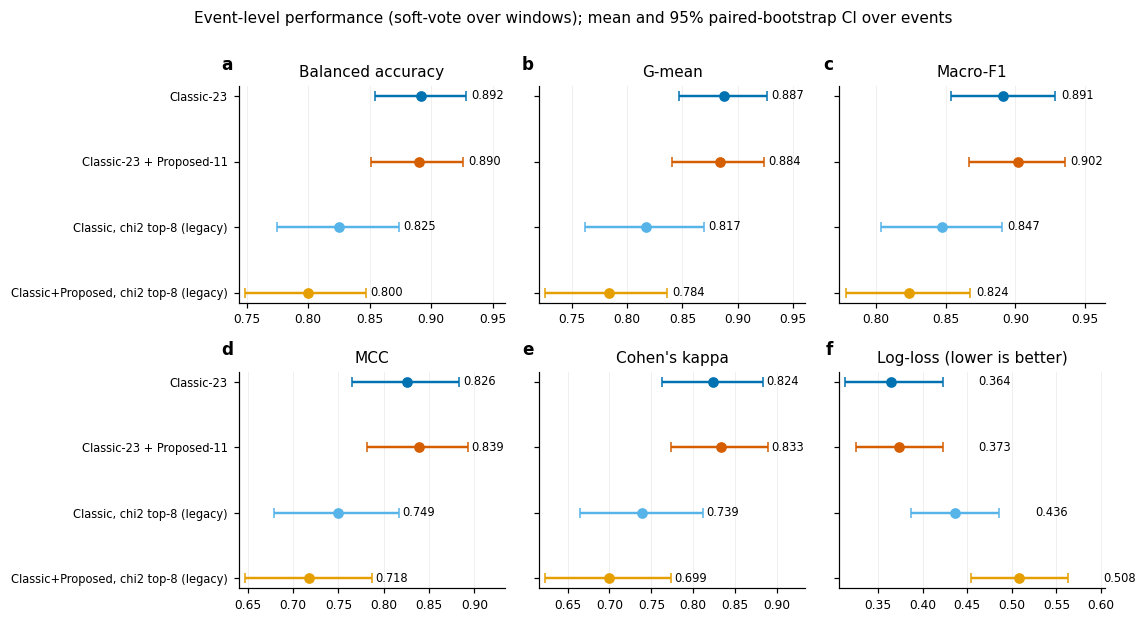

Saved fig1_metrics_with_CI.png / .pdf


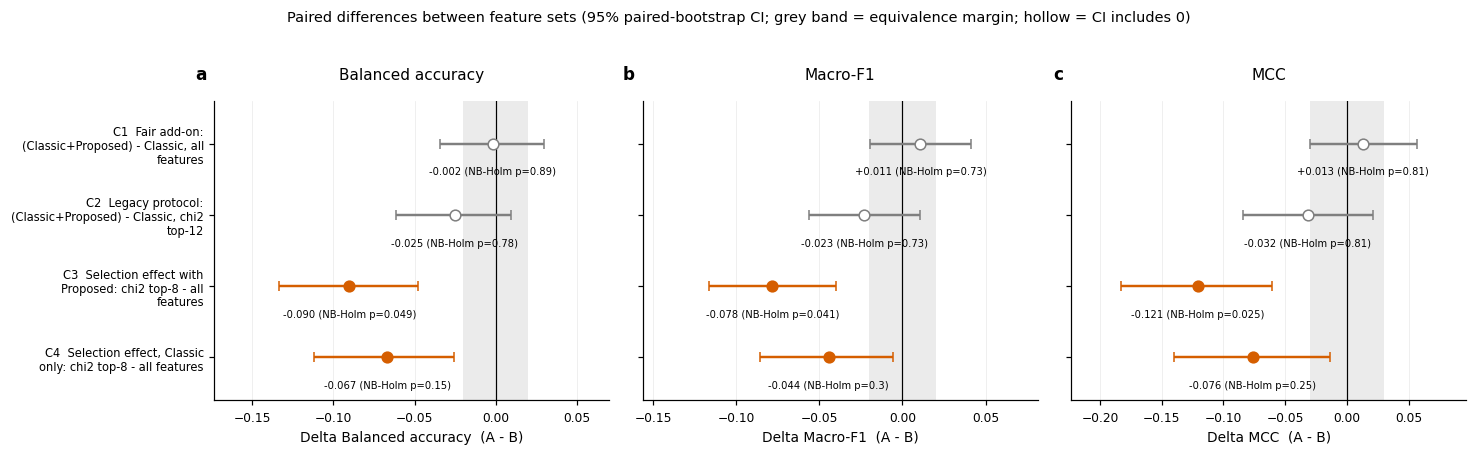

Saved fig2_paired_differences_forest.png / .pdf


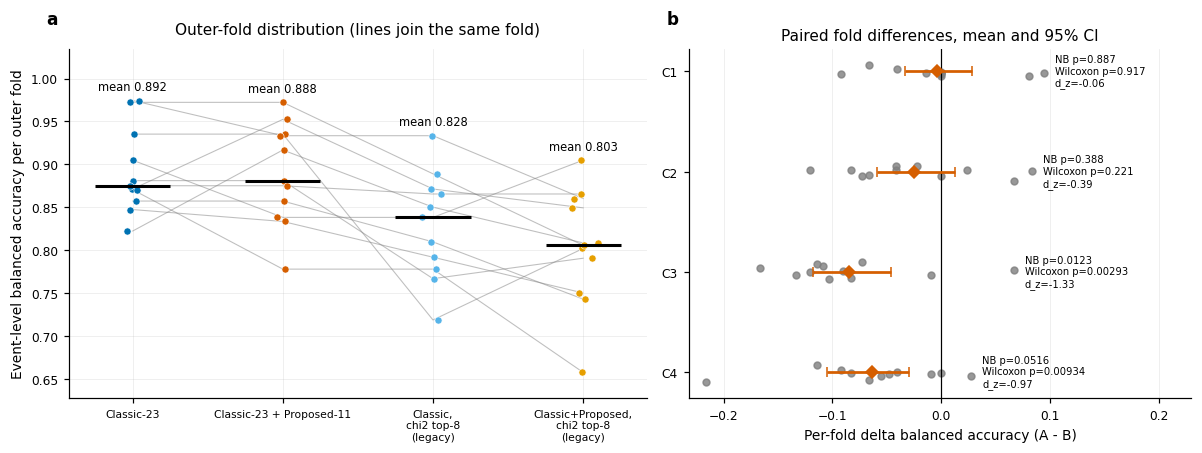

Saved fig3_cv_fold_distributions.png / .pdf


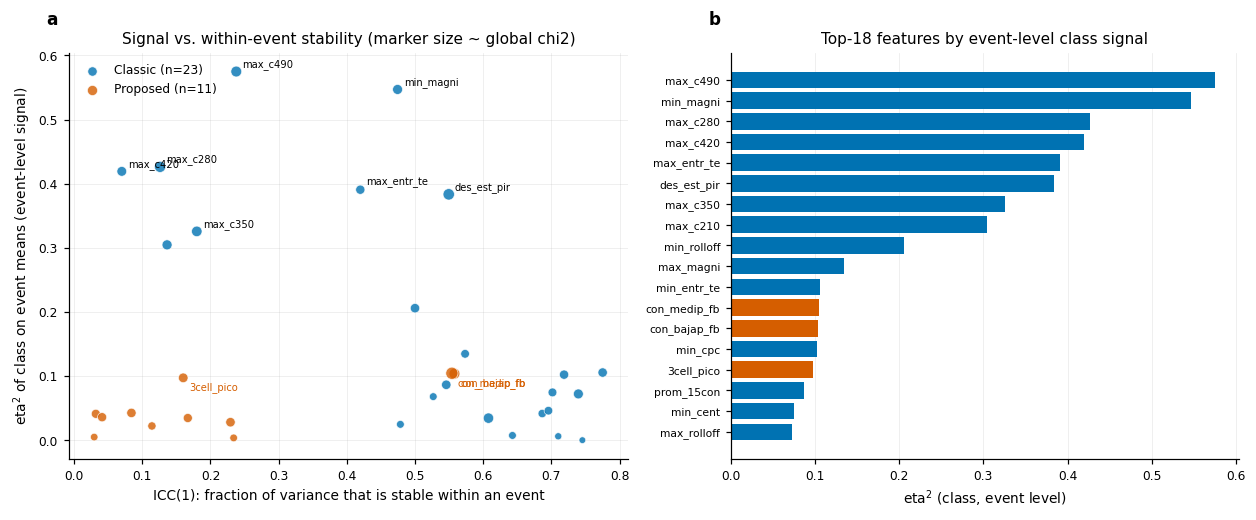

Saved fig4_feature_signal_vs_stability.png / .pdf


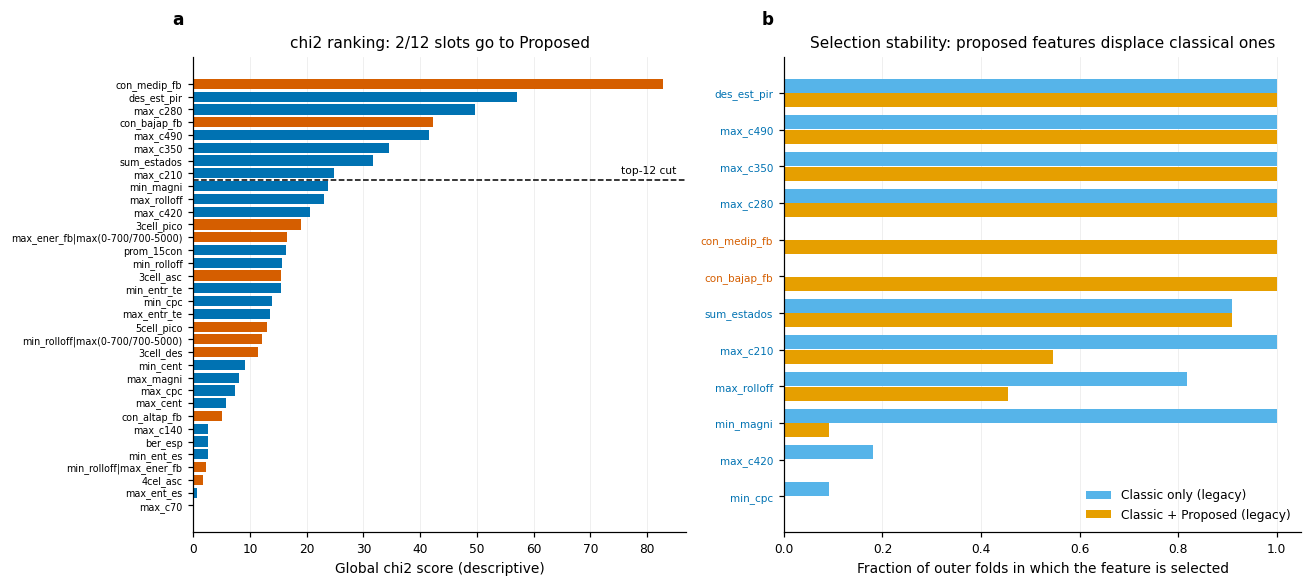

Saved fig5_chi2_selection_mechanism.png / .pdf


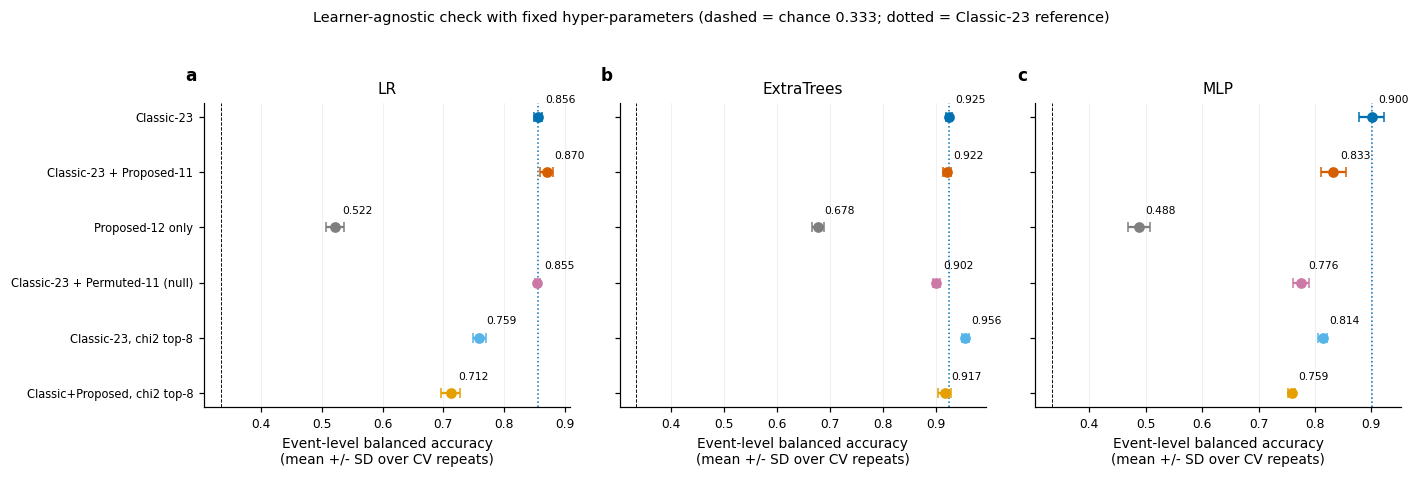

Saved fig6_learner_agnostic_robustness.png / .pdf


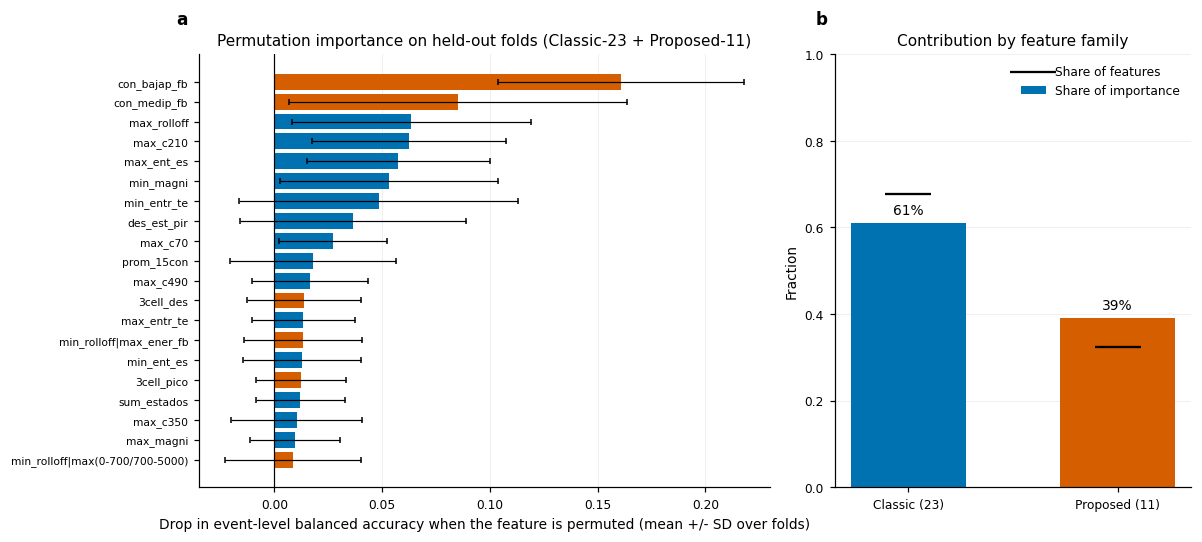

Saved fig7_permutation_importance.png / .pdf


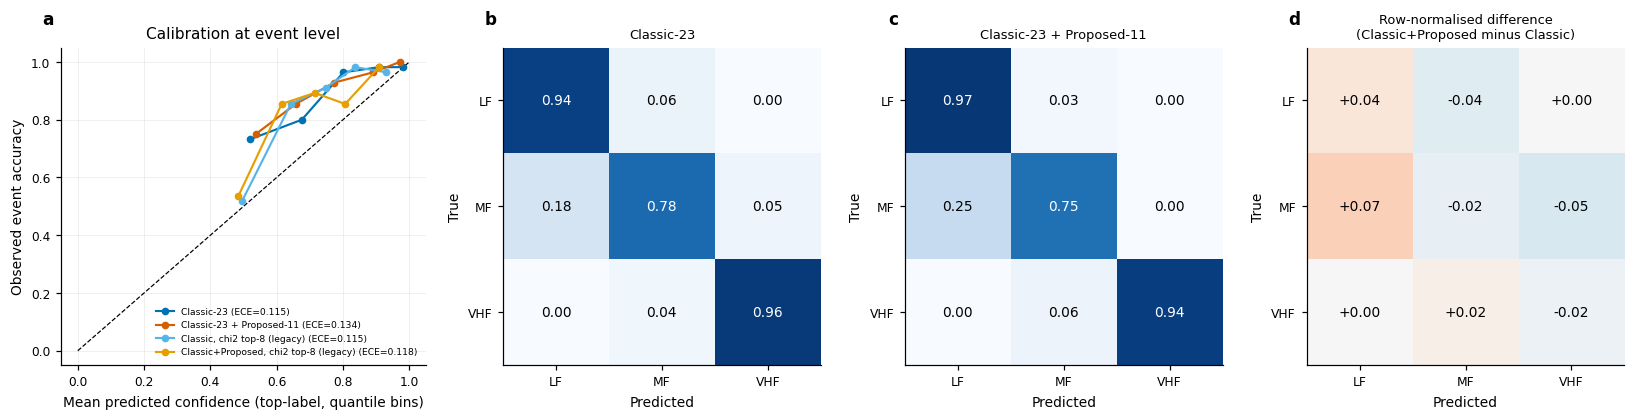

Saved fig8_calibration_and_confusion.png / .pdf

QUANTITATIVE CONCLUSION (event-level balanced accuracy)
C1 fair add-on  : delta=-0.0019 [95% CI -0.0342, +0.0299], NB-Holm p=0.887, McNemar-Holm p=0.791 -> inconclusive
C2 legacy       : delta=-0.0252 [95% CI -0.0612, +0.0092], NB-Holm p=0.777 -> inconclusive
C3 selection    : delta=-0.0901 [95% CI -0.1333, -0.0478], NB-Holm p=0.0492 -> A < B (significant)
Permutation-importance share: Classic 61% | Proposed 39% (features: 66% / 34%)
Median ICC  Classic=0.55 vs Proposed=0.16;  median eta2(event) Classic=0.10 vs Proposed=0.04
ECE (event-level): Classic-23=0.115, Classic-23 + Proposed-11=0.134, Classic, chi2 top-8 (legacy)=0.115, Classic+Proposed, chi2 top-8 (legacy)=0.118

Total run time: 8292 s


In [10]:
# ==============================================================================
# 8. MAIN
# ==============================================================================
def main():
    t_start = time.time()
    df, y, groups, le, info = load_data()
    K = len(le.classes_); class_names = [str(c) for c in le.classes_]
    print(f"PROFILE={PROFILE} | outer={N_OUTER_FOLDS} inner={N_INNER_FOLDS} trials={N_TRIALS} boot={N_BOOTSTRAP} | sklearn {sklearn.__version__}", flush=True)
    print("DATA AUDIT:", json.dumps(info), flush=True)
    print("Classes:", dict(zip(class_names, np.bincount(y))), flush=True)
    fd = feature_diagnostics(df, y, groups); fd.round(4).to_csv(_p("feature_diagnostics.csv"), index=False)
    grp = fd.groupby("type")[["icc_event", "eta2_event", "eta2_window"]].median().round(3)
    print("\nMedian stability / signal by feature family (ICC = within-event stability, eta2 = class signal at event level):\n", grp.to_string(), flush=True)

    G = groups[:, None].astype(float)
    cols_c, cols_cp = ACOUSTIC_COLS, ACOUSTIC_COLS + PROPOSED_COLS
    CONFIGS = [  # name, columns, k_features, permutation importance?
        ("Classic-23 (all)", cols_c, None, False),
        ("Classic-23 + Proposed-11 (all)", cols_cp, None, True),
        ("Classic Features", cols_c, K_LEGACY, False),                 # legacy replicate
        ("Classic Features + proposed", cols_cp, K_LEGACY, False)]     # legacy replicate
    results = {}
    for i, (name, cols, k, pi) in enumerate(CONFIGS, 1):
        print("\n" + "=" * 78 + f"\nConfig {i}/{len(CONFIGS)}: {name}  [{len(cols)} columns, chi2 top-k={k}]\n" + "=" * 78, flush=True)
        Xg = np.hstack([df[cols].to_numpy(float), G])
        results[name] = run_nested_cv_experiment(name, Xg, y, groups, K, class_names, cols, k_features=k, perm_importance=pi)

    order = [c[0] for c in CONFIGS]
    boot_idx = make_boot_indices(len(results[order[0]]["y_true"]), N_BOOTSTRAP)
    # validate fast metric implementation against sklearn on the observed data
    for c in order:
        r = results[c]; a = compute_all_metrics(r["y_true"], r["y_pred"], r["y_proba"], K); b = fast_metrics(r["y_true"], r["y_pred"], r["y_proba"], K)
        assert all(abs(a[m] - b[m]) < 1e-6 for m in METRIC_ORDER), f"fast_metrics mismatch for {c}"
    boot_raw = {}
    for c in order:
        r = results[c]; r["boot_summary"], r["boot_raw"] = bootstrap_metrics(r["y_true"], r["y_pred"], r["y_proba"], K, boot_idx); boot_raw[c] = r["boot_raw"]

    # ---------------- reports ----------------
    for title, key in [("Window-level grouped 11-fold CV (cv_mean / cv_std over outer folds)", "cv_summary"),
                       ("Event-level paired bootstrap (mean, std, 95% CI)", "boot_summary")]:
        print("\n" + "#" * 78 + f"\n# {title}\n" + "#" * 78, flush=True)
        for c in order: print(f"\n--- {c} ---\n{results[c][key].to_string()}", flush=True)
    print("\n" + "#" * 78 + "\n# Per-class event-level metrics\n" + "#" * 78, flush=True)
    for c in order: print(f"\n--- {c} ---\n{results[c]['per_class'].round(4).to_string(index=False)}", flush=True)
    print("\nHard-vote vs soft-vote disagreement (share of events; v1 used hard vote):", {c: round(results[c]['hard_vs_soft'], 3) for c in order}, flush=True)
    hb = {c: float(np.mean([u >= UNITS_MAX - 5 for h in results[c]['fold_table']['best_hidden_layer_sizes'] for u in h])) for c in order}
    print("Share of tuned layers within 5 units of the search-space upper bound:", {c: round(v, 2) for c, v in hb.items()}, flush=True)

    S = statistical_analysis(results, boot_raw, N_BOOTSTRAP)
    keep = ["contrast", "metric", "delta_event", "ci95_lo", "ci95_hi", "p_boot_holm", "p_nadeau_bengio", "p_nadeau_bengio_holm", "p_wilcoxon", "p_sign",
            "folds_A_better", "folds_B_better", "hedges_gz", "cliffs_delta", "mcnemar_A_only_correct", "mcnemar_B_only_correct", "p_mcnemar_holm", "equivalent", "verdict"]
    pd.set_option("display.width", 250, "display.max_columns", 50, "display.max_colwidth", 70)
    print("\n" + "#" * 78 + "\n# PAIRED STATISTICAL TESTS (A - B; event-level; Holm across contrasts within each metric)\n" + "#" * 78, flush=True)
    print(S[keep].round(4).to_string(index=False), flush=True)
    S.to_csv(_p("statistical_tests.csv"), index=False)

    print("\n" + "#" * 78 + "\n# LEARNER-AGNOSTIC ROBUSTNESS (fixed hyper-parameters)\n" + "#" * 78, flush=True)
    rob, sets = run_robustness(df, y, groups, K)
    rsum = rob.groupby(["learner", "feature_set"], sort=False)[["ba_window", "ba_event", "mcc_event"]].agg(["mean", "std"]).round(4)
    print(rsum.to_string(), flush=True); rsum.to_csv(_p("robustness_summary.csv"))

    # ---------------- exports (original file names preserved for the legacy configs) ----------------
    for c, r in results.items():
        sn = c.replace(" ", "_").replace("(", "").replace(")", "").replace("+", "y")
        r["fold_table"].to_csv(_p(f"fold_table_{sn}.csv")); r["boot_summary"].to_csv(_p(f"bootstrap_summary_{sn}.csv")); r["per_class"].to_csv(_p(f"per_class_{sn}.csv"), index=False)
    pd.concat({c: results[c]["boot_summary"]["mean"] for c in order}, axis=1).round(4).to_csv(_p("consolidated_bootstrap_means.csv"))
    json.dump(dict(profile=PROFILE, seed=RANDOM_STATE, python=platform.python_version(), sklearn=sklearn.__version__, numpy=np.__version__,
                   pandas=pd.__version__, optuna=optuna.__version__, data=info, outer=N_OUTER_FOLDS, inner=N_INNER_FOLDS, trials=N_TRIALS, boot=N_BOOTSTRAP),
              open(_p("run_manifest.json"), "w"), indent=2, default=str)

    # ---------------- figures ----------------
    fig1_metrics(results, order); fig2_paired_differences(S); fig3_cv_distributions(results, order, S)
    fig4_signal_vs_stability(fd); fig5_selection_mechanism(fd, results, cols_cp); fig6_robustness(rob, sets)
    share = fig7_permutation_importance(results["Classic-23 + Proposed-11 (all)"], fd); ece = fig8_calibration_confusion(results, order, class_names, K)

    # ---------------- quantitative conclusion ----------------
    def g(ci, m="balanced_accuracy"): return S[(S.contrast.str.startswith(ci)) & (S.metric == m)].iloc[0]
    c1, c2, c3 = g("C1"), g("C2"), g("C3")
    print("\n" + "=" * 78 + "\nQUANTITATIVE CONCLUSION (event-level balanced accuracy)\n" + "=" * 78)
    print(f"C1 fair add-on  : delta={c1.delta_event:+.4f} [95% CI {c1.ci95_lo:+.4f}, {c1.ci95_hi:+.4f}], NB-Holm p={c1.p_nadeau_bengio_holm:.3g}, McNemar-Holm p={c1.p_mcnemar_holm:.3g} -> {c1.verdict}")
    print(f"C2 legacy       : delta={c2.delta_event:+.4f} [95% CI {c2.ci95_lo:+.4f}, {c2.ci95_hi:+.4f}], NB-Holm p={c2.p_nadeau_bengio_holm:.3g} -> {c2.verdict}")
    print(f"C3 selection    : delta={c3.delta_event:+.4f} [95% CI {c3.ci95_lo:+.4f}, {c3.ci95_hi:+.4f}], NB-Holm p={c3.p_nadeau_bengio_holm:.3g} -> {c3.verdict}")
    print(f"Permutation-importance share: Classic {share['Classic']*100:.0f}% | Proposed {share['Proposed']*100:.0f}% (features: 66% / 34%)")
    print(f"Median ICC  Classic={grp.loc['Classic','icc_event']:.2f} vs Proposed={grp.loc['Proposed','icc_event']:.2f};  median eta2(event) Classic={grp.loc['Classic','eta2_event']:.2f} vs Proposed={grp.loc['Proposed','eta2_event']:.2f}")
    print(f"ECE (event-level): " + ", ".join(f"{SHORT[c]}={v:.3f}" for c, v in ece.items()))
    print(f"\nTotal run time: {time.time()-t_start:.0f} s", flush=True)
    return results, S, rob, fd

if __name__ == "__main__":
    results, S, rob, fd = main()
